In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.optimize import Bounds, LinearConstraint, milp
from statsmodels.stats.multitest import multipletests


# ============================================================
# DATA
# ============================================================

base_dir = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/"
    "preprocessing/pkl_files_filtered"
)

file_dict = {
    "treutlein": base_dir / "treutlein_all_genes.pkl",
    "weinreb": base_dir / "weinreb_all_genes.pkl",
    "junker": base_dir / "junker_z5_all_genes.pkl",

    "you1": base_dir / "you_stage1_barcode_all_genes.pkl",
    "you2": base_dir / "you_stage2_barcode_all_genes.pkl",
    "you3": base_dir / "you_stage3_barcode_all_genes.pkl",
    "you4": base_dir / "you_stage4_barcode_all_genes.pkl",

    "knoblich_day16_1": base_dir / "knoblich_day16_1.pkl",
    "knoblich_day16_2": base_dir / "knoblich_day16_2.pkl",
    "knoblich_day42_1": base_dir / "knoblich_day42_1.pkl",
    "knoblich_day42_2": base_dir / "knoblich_day42_2.pkl",
}

name_map = {
    "treutlein": "HBO1",
    "weinreb": "MHSPC",
    "junker": "ZFL",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4",
}

dataset_order = [
    "HBO1", "MHSPC", "ZFL",
    "HBO2_16_1", "HBO2_16_2", "HBO2_42_1", "HBO2_42_2",
    "HBO3_1", "HBO3_2", "HBO3_3", "HBO3_4",
]


# ============================================================
# NEW OUTPUT DIRECTORY — does not overwrite MT-only analysis
# ============================================================

MATCH_OUT_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/analysis/"
    "MT_autophagy_ncMT_expression_matching"
)
MATCH_OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# MATCHING SETTINGS
# ============================================================

N_MATCHED_SETS = 1000
MATCH_TOLERANCE = 0.03
SEED_TOLERANCE = 0.01
RANDOM_SEED = 42
MAX_RANDOM_WALK_STEPS = 20000

# Fast/resume settings
RESUME_COMPLETED = True
USE_ORIGINAL_MT_MATCHES = True

ORIGINAL_MT_MATCH_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/analysis/"
    "MT_set_level_matching"
)

# We only need a FEASIBLE seed, not the globally optimal MILP solution.
# Try small candidate pools first; this prevents the huge all-gene MILPs
# used in the previous combined notebook.
SEED_POOL_SIZES = [750, 1500, 3000, 5000]
SEED_TOLERANCES = [0.01, 0.02, MATCH_TOLERANCE]
MILP_TIME_LIMIT_SECONDS = 15


# Mirrors the old MT notebook: when matching one target set,
# only genes from that target set are excluded from controls.
# Set True if you instead want MT/autophagy/ncMT all excluded
# from every control pool.
EXCLUDE_ALL_SPECIAL_GENE_SETS_FROM_CONTROLS = False

GENE_SET_ORDER = ["MT", "Autophagy", "ncMT"]

# Deterministic offsets so every dataset/gene-set combination gets
# its own reproducible random stream.
GENE_SET_SEED_OFFSET = {
    "MT": 0,
    "Autophagy": 100000,
    "ncMT": 200000,
}


## Gene-set definitions

In [2]:
# ============================================================
# AUTOPHAGY GENES
# Exact definitions from cell_type_analysis.ipynb
# ============================================================

autophagy_genes = [
    "ATG5", "ATG7", "BECN1", "MAP1LC3B", "SQSTM1", "GABARAPL1",
    "ULK1", "WIPI2", "ATG12", "ATG16L1", "VPS34", "UVRAG",
    "PINK1", "PRKN", "BNIP3", "DRAM1", "GABARAP", "LC3B",
    "ATG4B", "RUBCN", "FIP200", "AMBRA1"
]

zebrafish_autophagy_genes = [
    "atg5", "atg7", "becn1", "map1lc3b", "sqstm1", "gabarapl1",
    "ulk1", "wipi2", "atg12", "atg16l1", "pik3c3", "uvrag",
    "pink1", "parkin", "bnip3", "dram1", "gabarap", "map1lc3b",
    "atg4b", "rubcn", "rb1cc1", "ambra1"
]

mouse_autophagy_genes = [
    "Atg5", "Atg7", "Becn1", "Map1lc3b", "Sqstm1", "Gabarapl1",
    "Ulk1", "Wipi2", "Atg12", "Atg16l1", "Pik3c3", "Uvrag",
    "Pink1", "Prkn", "Bnip3", "Dram1", "Gabarap", "Map1lc3b",
    "Atg4b", "Rubcn", "Rb1cc1", "Ambra1"
]

AUTOPHAGY_GENES = set(
    autophagy_genes
    + zebrafish_autophagy_genes
    + mouse_autophagy_genes
)


# ============================================================
# NUCLEAR-ENCODED MITOCHONDRIAL / ncMT GENES
# Exact mitochondrial_related_genes definitions from
# cell_type_analysis.ipynb (shown there as "Nuclear MT genes")
# ============================================================

zebrafish_ncmt_genes = [
    "ndufs1", "sdha", "uqcrc1", "cox4i1", "atp5f1a",
    "ppargc1a", "tfam", "twinkle", "polg",
    "tomm20a", "timm23", "hspa9",
    "mrpl12", "mrps22",
    "sod2", "gpx4a", "prdx3",
    "mfn1", "mfn2", "opa1", "dnm1l",
    "bcl2", "cycs",
    "idh3a", "cpt1a", "glud1a",
    "atf4a", "chop"
]

mouse_ncmt_genes = [
    "Ndufs1", "Sdha", "Uqcrc1", "Cox4i1", "Atp5f1a",
    "Ppargc1a", "Tfam", "Twnk", "Polg",
    "Tomm20", "Timm23", "Hspa9",
    "Mrpl12", "Mrps22",
    "Sod2", "Gpx4", "Prdx3",
    "Mfn1", "Mfn2", "Opa1", "Dnm1l",
    "Bcl2", "Cycs",
    "Idh3a", "Cpt1a", "Glud1",
    "Atf4", "Chop"
]

human_ncmt_genes = [
    "NDUFS1", "SDHA", "UQCRC1", "COX4I1", "ATP5F1A",
    "PPARGC1A", "TFAM", "TWNK", "POLG",
    "TOMM20", "TIMM23", "HSPA9",
    "MRPL12", "MRPS22",
    "SOD2", "GPX4", "PRDX3",
    "MFN1", "MFN2", "OPA1", "DNM1L",
    "BCL2", "CYCS",
    "IDH3A", "CPT1A", "GLUD1",
    "ATF4", "CHOP"
]

NCMT_GENES = set(
    human_ncmt_genes
    + zebrafish_ncmt_genes
    + mouse_ncmt_genes
)


## Calculate gene-level matching covariates

In [3]:
def calculate_gene_covariates(full_df):
    """
    Last dataframe column = lineage barcode.

    Returns one row per unique gene with:
        - mean expression
        - detection frequency
        - expression variance
        - membership in MT / Autophagy / ncMT

    MT membership is intentionally defined exactly as in the original
    Mitochondrial_Expression_Matching notebook.
    """

    gene_data = full_df.iloc[:, :-1]

    rows = []

    for j, gene in enumerate(gene_data.columns):
        x = gene_data.iloc[:, j].to_numpy()

        rows.append({
            "gene": str(gene),
            "mean_expression": np.mean(x),
            "detection_frequency": np.mean(x > 0),
            "expression_variance": np.var(x),
        })

    gene_stats = pd.DataFrame(rows)

    # Collapse duplicate gene names exactly as in the MT notebook.
    gene_stats = (
        gene_stats
        .groupby("gene", as_index=False)
        .agg({
            "mean_expression": "mean",
            "detection_frequency": "mean",
            "expression_variance": "mean",
        })
    )

    gene_stats["is_MT"] = (
        gene_stats["gene"]
        .str.lower()
        .str.startswith("mt-")
    )

    gene_stats["is_Autophagy"] = gene_stats["gene"].isin(AUTOPHAGY_GENES)
    gene_stats["is_ncMT"] = gene_stats["gene"].isin(NCMT_GENES)

    return gene_stats


def target_column(gene_set):
    return {
        "MT": "is_MT",
        "Autophagy": "is_Autophagy",
        "ncMT": "is_ncMT",
    }[gene_set]


def get_target_and_control_df(gene_stats, gene_set):
    """Return observed target genes and the eligible control pool."""

    target_col = target_column(gene_set)
    target_df = gene_stats.loc[gene_stats[target_col]].copy().reset_index(drop=True)

    if EXCLUDE_ALL_SPECIAL_GENE_SETS_FROM_CONTROLS:
        special_mask = gene_stats[["is_MT", "is_Autophagy", "is_ncMT"]].any(axis=1)
        ctrl_df = gene_stats.loc[~special_mask].copy().reset_index(drop=True)
    else:
        # This mirrors the original MT notebook: exclude only the target set.
        ctrl_df = gene_stats.loc[~gene_stats[target_col]].copy().reset_index(drop=True)

    if len(target_df) == 0:
        raise ValueError(f"No {gene_set} genes are present in this dataset.")

    if len(ctrl_df) < len(target_df):
        raise ValueError(
            f"Not enough control genes for {gene_set}: "
            f"{len(ctrl_df)} controls for {len(target_df)} target genes."
        )

    return target_df, ctrl_df


## Sanity check: genes present in each dataset

In [4]:
gene_count_rows = []

for dataset, pkl_path in file_dict.items():
    full_df = pd.read_pickle(pkl_path)
    gene_stats = calculate_gene_covariates(full_df)
    del full_df

    for gene_set in GENE_SET_ORDER:
        target_df, ctrl_df = get_target_and_control_df(gene_stats, gene_set)

        gene_count_rows.append({
            "dataset": dataset,
            "dataset_label": name_map[dataset],
            "gene_set": gene_set,
            "n_target_genes": len(target_df),
            "n_control_pool": len(ctrl_df),
            "target_genes": ", ".join(target_df["gene"].astype(str).tolist()),
        })

gene_count_df = pd.DataFrame(gene_count_rows)
display(gene_count_df[[
    "dataset_label", "gene_set", "n_target_genes", "n_control_pool"
]])


,dataset_label,gene_set,n_target_genes,n_control_pool
0,HBO1,MT,13,20843
1,HBO1,Autophagy,18,20838
2,HBO1,ncMT,25,20831
3,MHSPC,MT,13,22623
4,MHSPC,Autophagy,20,22616
5,MHSPC,ncMT,25,22611
6,ZFL,MT,13,21049
7,ZFL,Autophagy,15,21047
8,ZFL,ncMT,19,21043
9,HBO3_1,MT,13,25336


In [5]:
MATCH_METRICS = [
    "mean_expression",
    "detection_frequency",
    "expression_variance",
]


def _check_seed(ctrl_df, selected_idx, target, scale, n_target, tolerance):
    """Validate a candidate seed and return its maximum relative error."""
    selected_idx = np.asarray(selected_idx, dtype=int)

    if len(selected_idx) != n_target or len(np.unique(selected_idx)) != n_target:
        return None

    means = ctrl_df.iloc[selected_idx][MATCH_METRICS].mean().to_numpy(dtype=float)
    signed_error = (means - target) / scale
    max_error = np.abs(signed_error).max()

    if max_error <= tolerance + 1e-10:
        return float(max_error)

    return None


def find_feasible_seed_fast(
    gene_stats,
    gene_set,
    pool_sizes=SEED_POOL_SIZES,
    tolerances=SEED_TOLERANCES,
    time_limit=MILP_TIME_LIMIT_SECONDS,
):
    """
    Find ONE feasible matched control set quickly.

    Important difference from the previous combined notebook:
    ---------------------------------------------------------
    We do NOT ask MILP to optimize a distance objective over every gene.
    We only ask whether a valid set exists (objective = 0), and initially
    restrict the binary variables to genes closest to the target covariates.

    This is sufficient because the seed is only a starting point for the
    feasible random walk. MI is never used here.
    """

    target_df, ctrl_df = get_target_and_control_df(gene_stats, gene_set)

    n_target = len(target_df)
    target = target_df[MATCH_METRICS].mean().to_numpy(dtype=float)
    scale = np.maximum(np.abs(target), 1e-12)

    ctrl_values_all = ctrl_df[MATCH_METRICS].to_numpy(dtype=float)

    # Rank genes only to define a compact search pool.
    # This is O(number of genes), unlike solving the original all-gene MILP.
    standardized_distance = np.sum(
        ((ctrl_values_all - target[None, :]) / scale[None, :]) ** 2,
        axis=1,
    )
    ranked_idx = np.argsort(standardized_distance)

    # Try progressively larger pools. The final option can include all genes,
    # but remains time-limited and is a pure feasibility problem.
    pools_to_try = []
    for p in pool_sizes:
        p = min(int(p), len(ctrl_df))
        if p >= n_target and p not in pools_to_try:
            pools_to_try.append(p)

    if len(ctrl_df) not in pools_to_try:
        pools_to_try.append(len(ctrl_df))

    for tolerance in tolerances:
        for pool_size in pools_to_try:
            pool_global_idx = ranked_idx[:pool_size]
            pool_values = ctrl_values_all[pool_global_idx]

            n_ctrl = len(pool_global_idx)
            integrality = np.ones(n_ctrl, dtype=int)
            bounds = Bounds(np.zeros(n_ctrl), np.ones(n_ctrl))

            A = np.vstack([
                np.ones(n_ctrl),
                pool_values.T,
            ])

            lower_metric = n_target * target * (1 - tolerance)
            upper_metric = n_target * target * (1 + tolerance)

            lb = np.concatenate([[n_target], lower_metric])
            ub = np.concatenate([[n_target], upper_metric])
            constraints = LinearConstraint(A, lb, ub)

            # ZERO objective = feasibility only. There is no reason to spend
            # time proving that one feasible seed is "optimal".
            result = milp(
                c=np.zeros(n_ctrl, dtype=float),
                integrality=integrality,
                bounds=bounds,
                constraints=constraints,
                options={
                    "disp": False,
                    "presolve": True,
                    "time_limit": float(time_limit),
                },
            )

            if result.x is None:
                continue

            selected_local = np.flatnonzero(result.x > 0.5)
            selected_global = pool_global_idx[selected_local]

            max_error = _check_seed(
                ctrl_df=ctrl_df,
                selected_idx=selected_global,
                target=target,
                scale=scale,
                n_target=n_target,
                tolerance=tolerance,
            )

            if max_error is not None:
                seed_genes = (
                    ctrl_df.iloc[selected_global]["gene"]
                    .astype(str)
                    .tolist()
                )

                print(
                    f"{gene_set}: feasible seed found | "
                    f"pool={pool_size:,} genes | "
                    f"constraint={100*tolerance:.1f}% | "
                    f"actual max error={100*max_error:.3f}%"
                )
                return seed_genes

    raise RuntimeError(
        f"{gene_set}: no feasible seed was found within the bounded search. "
        "This is now a real matching-feasibility issue rather than an "
        "unbounded runtime issue. You can increase SEED_POOL_SIZES or "
        "MILP_TIME_LIMIT_SECONDS for this one dataset if necessary."
    )


## Expand each seed to 1,000 feasible matched sets

In [6]:
def expand_feasible_matched_sets(
    gene_stats,
    gene_set,
    seed_genes,
    n_sets=N_MATCHED_SETS,
    tolerance=MATCH_TOLERANCE,
    random_seed=RANDOM_SEED,
    max_steps=MAX_RANDOM_WALK_STEPS,
):
    """
    Generate diverse matched control sets by random walking through
    feasible set space.

    Compared with the previous combined notebook, a step now tries ALL
    possible removal positions in random order until it finds one with a
    feasible replacement. Therefore a state cannot silently spend tens of
    thousands of iterations repeatedly choosing an impossible removal.

    Every retained set:
        - has exactly the same number of genes as the observed gene set
        - contains no genes from the current target set
        - differs by <= tolerance from the target set for:
            * mean expression
            * detection frequency
            * expression variance

    MI is never used in matching.
    """

    rng = np.random.default_rng(random_seed)

    target_df, ctrl_df = get_target_and_control_df(gene_stats, gene_set)
    n_target = len(target_df)

    target = target_df[MATCH_METRICS].mean().to_numpy(dtype=float)
    scale = np.maximum(np.abs(target), 1e-12)

    ctrl_values = ctrl_df[MATCH_METRICS].to_numpy(dtype=float)
    ctrl_genes = ctrl_df["gene"].astype(str).to_numpy()

    gene_to_idx = {gene: i for i, gene in enumerate(ctrl_genes)}

    missing = [g for g in seed_genes if g not in gene_to_idx]
    if missing:
        raise ValueError(f"Seed genes missing from control pool: {missing}")

    seed_selected = np.array([gene_to_idx[g] for g in seed_genes], dtype=int)

    if len(seed_selected) != n_target:
        raise ValueError(
            f"Seed contains {len(seed_selected)} genes; expected {n_target}."
        )

    selected = seed_selected.copy()
    seed_sum = ctrl_values[seed_selected].sum(axis=0)
    current_sum = seed_sum.copy()

    def evaluate_sum(xsum):
        means = xsum / n_target
        signed_error = (means - target) / scale
        max_error = np.abs(signed_error).max()
        return max_error, means, signed_error

    score, _, _ = evaluate_sum(current_sum)
    if score > tolerance:
        raise ValueError(
            f"Starting seed is not feasible: {100*score:.3f}% maximum mismatch."
        )

    seen = set()
    set_rows = []
    gene_rows = []

    def save_current_set():
        key = tuple(sorted(ctrl_genes[selected]))
        if key in seen:
            return False

        score, means, errors = evaluate_sum(current_sum)
        if score > tolerance:
            return False

        seen.add(key)
        set_id = len(seen)

        set_rows.append({
            "set_id": set_id,
            "mean_expression": means[0],
            "detection_frequency": means[1],
            "expression_variance": means[2],
            "rel_error_expression": errors[0],
            "rel_error_detection": errors[1],
            "rel_error_variance": errors[2],
            "max_rel_error": score,
        })

        for gene in ctrl_genes[selected]:
            gene_rows.append({"set_id": set_id, "gene": gene})

        return True

    save_current_set()

    successful_moves = 0
    dead_end_restarts = 0
    moves_since_new_set = 0

    while len(seen) < n_sets and successful_moves < max_steps:
        moved = False

        # Try every removal position once, in random order.
        # Usually the first one works; this only becomes more thorough when
        # the feasible space is tight.
        for out_pos in rng.permutation(n_target):
            old_idx = selected[out_pos]
            sum_without = current_sum - ctrl_values[old_idx]

            proposed_means = (sum_without[None, :] + ctrl_values) / n_target
            relative_errors = (proposed_means - target[None, :]) / scale[None, :]
            max_errors = np.max(np.abs(relative_errors), axis=1)

            valid = max_errors <= tolerance
            valid[selected] = False

            candidate_idx = np.flatnonzero(valid)
            if len(candidate_idx) == 0:
                continue

            candidate_scores = max_errors[candidate_idx]
            weights = tolerance - candidate_scores + 1e-6
            weights = weights / weights.sum()

            new_idx = rng.choice(candidate_idx, p=weights)
            selected[out_pos] = new_idx
            current_sum = sum_without + ctrl_values[new_idx]

            moved = True
            successful_moves += 1

            if save_current_set():
                moves_since_new_set = 0
            else:
                moves_since_new_set += 1

            break

        if not moved:
            # This particular feasible state is isolated under one-gene swaps.
            # Restart from the known-good seed rather than silently burning
            # through 200,000 failed random proposals.
            selected = seed_selected.copy()
            current_sum = seed_sum.copy()
            dead_end_restarts += 1
            moves_since_new_set = 0

            if dead_end_restarts > 25:
                raise RuntimeError(
                    f"{gene_set}: repeatedly reached one-swap dead ends after "
                    f"generating {len(seen)}/{n_sets} sets. The feasible space "
                    "is unusually disconnected; use a second feasible seed for "
                    "this dataset rather than increasing the loop to hours."
                )

        # If the walk keeps revisiting old states, restart instead of wandering
        # indefinitely in the same small component.
        if moves_since_new_set >= 500:
            selected = seed_selected.copy()
            current_sum = seed_sum.copy()
            moves_since_new_set = 0
            dead_end_restarts += 1

        if successful_moves > 0 and successful_moves % 1000 == 0:
            print(
                f"{gene_set} | successful moves: {successful_moves} | "
                f"unique sets: {len(seen)}/{n_sets} | "
                f"restarts: {dead_end_restarts}",
                end="\r",
            )

    print()
    print(
        f"{gene_set}: finished with {len(seen)} unique sets after "
        f"{successful_moves} successful moves "
        f"({dead_end_restarts} restarts)."
    )

    if len(seen) < n_sets:
        raise RuntimeError(
            f"{gene_set}: only generated {len(seen)}/{n_sets} matched sets "
            f"after {successful_moves} successful moves."
        )

    return pd.DataFrame(set_rows), pd.DataFrame(gene_rows)


## Run matching for all 3 gene sets × 11 datasets

In [7]:
all_matched_qc = []
all_observed_qc = []


def _load_if_complete(qc_path, genes_path, expected_sets=N_MATCHED_SETS):
    """Load an existing result only if it is complete and internally sane."""
    if not qc_path.exists() or not genes_path.exists():
        return None

    qc = pd.read_csv(qc_path)
    genes = pd.read_csv(genes_path)

    if len(qc) != expected_sets:
        return None

    if qc["set_id"].nunique() != expected_sets:
        return None

    if genes["set_id"].nunique() != expected_sets:
        return None

    if (qc["max_rel_error"] > MATCH_TOLERANCE + 1e-10).any():
        return None

    return qc, genes


for dataset_index, (dataset, pkl_path) in enumerate(file_dict.items()):
    print("\n" + "=" * 80)
    print(dataset, "|", name_map[dataset])
    print("=" * 80)

    full_df = pd.read_pickle(pkl_path)
    gene_stats = calculate_gene_covariates(full_df)
    del full_df

    for gene_set in GENE_SET_ORDER:
        print("\n" + "-" * 60)
        print(gene_set)
        print("-" * 60)

        target_df, _ = get_target_and_control_df(gene_stats, gene_set)
        target_n = len(target_df)

        print("Observed genes:", target_n)
        print(target_df["gene"].astype(str).tolist())

        gene_set_dir = MATCH_OUT_DIR / gene_set
        gene_set_dir.mkdir(parents=True, exist_ok=True)

        qc_path = gene_set_dir / f"{dataset}_matched_set_QC_FINAL.csv"
        genes_path = gene_set_dir / f"{dataset}_matched_gene_sets_FINAL.csv"

        set_summary = None
        gene_selections = None

        # ====================================================
        # MT: reuse the ORIGINAL final MT matching exactly.
        # No new MT seed search or random walk is needed.
        # ====================================================
        if gene_set == "MT" and USE_ORIGINAL_MT_MATCHES:
            old_qc_path = ORIGINAL_MT_MATCH_DIR / f"{dataset}_matched_set_QC_FINAL.csv"
            old_genes_path = ORIGINAL_MT_MATCH_DIR / f"{dataset}_matched_gene_sets_FINAL.csv"

            old = _load_if_complete(old_qc_path, old_genes_path)

            if old is not None:
                set_summary, gene_selections = old

                # Save a copy in the combined-analysis directory so every
                # downstream cell can use one uniform path layout.
                set_summary.to_csv(qc_path, index=False)
                gene_selections.to_csv(genes_path, index=False)

                print("Reused original MT notebook's 1000 final matched sets.")
            else:
                print(
                    "Original MT FINAL files were not found/complete; "
                    "MT will be generated below."
                )

        # ====================================================
        # Autophagy/ncMT (or MT fallback): resume a completed
        # result from the previous partial combined run.
        # ====================================================
        if set_summary is None and RESUME_COMPLETED:
            existing = _load_if_complete(qc_path, genes_path)
            if existing is not None:
                set_summary, gene_selections = existing
                print("Found complete existing result -> skipping recomputation.")

        # ====================================================
        # Generate only if no complete result exists.
        # ====================================================
        if set_summary is None:
            seed_genes = find_feasible_seed_fast(
                gene_stats=gene_stats,
                gene_set=gene_set,
            )

            this_seed = (
                RANDOM_SEED
                + GENE_SET_SEED_OFFSET[gene_set]
                + dataset_index * 1000
            )

            set_summary, gene_selections = expand_feasible_matched_sets(
                gene_stats=gene_stats,
                gene_set=gene_set,
                seed_genes=seed_genes,
                n_sets=N_MATCHED_SETS,
                tolerance=MATCH_TOLERANCE,
                random_seed=this_seed,
                max_steps=MAX_RANDOM_WALK_STEPS,
            )

            set_summary.to_csv(qc_path, index=False)
            gene_selections.to_csv(genes_path, index=False)

        # ====================================================
        # Strict validation before proceeding
        # ====================================================
        if len(set_summary) != N_MATCHED_SETS:
            raise ValueError(
                f"{dataset} / {gene_set}: {len(set_summary)} sets found; "
                f"expected {N_MATCHED_SETS}."
            )

        if (set_summary["max_rel_error"] > MATCH_TOLERANCE + 1e-10).any():
            raise ValueError(
                f"{dataset} / {gene_set}: at least one set violates the "
                f"{100*MATCH_TOLERANCE:.1f}% tolerance."
            )

        counts_per_set = gene_selections.groupby("set_id")["gene"].nunique()
        if not (counts_per_set == target_n).all():
            raise ValueError(
                f"{dataset} / {gene_set}: matched sets do not all contain "
                f"exactly {target_n} unique genes."
            )

        set_summary = set_summary.copy()
        set_summary["dataset"] = dataset
        set_summary["dataset_label"] = name_map[dataset]
        set_summary["gene_set"] = gene_set
        all_matched_qc.append(set_summary)

        all_observed_qc.append(pd.DataFrame({
            "dataset": [dataset],
            "dataset_label": [name_map[dataset]],
            "gene_set": [gene_set],
            "n_genes": [target_n],
            "mean_expression": [target_df["mean_expression"].mean()],
            "detection_frequency": [target_df["detection_frequency"].mean()],
            "expression_variance": [target_df["expression_variance"].mean()],
        }))

matched_set_qc_final = pd.concat(all_matched_qc, ignore_index=True)
observed_qc_final = pd.concat(all_observed_qc, ignore_index=True)



treutlein | HBO1

------------------------------------------------------------
MT
------------------------------------------------------------
Observed genes: 13
['MT-ATP6', 'MT-ATP8', 'MT-CO1', 'MT-CO2', 'MT-CO3', 'MT-CYB', 'MT-ND1', 'MT-ND2', 'MT-ND3', 'MT-ND4', 'MT-ND4L', 'MT-ND5', 'MT-ND6']
Reused original MT notebook's 1000 final matched sets.

------------------------------------------------------------
Autophagy
------------------------------------------------------------
Observed genes: 18
['AMBRA1', 'ATG12', 'ATG16L1', 'ATG4B', 'ATG5', 'ATG7', 'BECN1', 'BNIP3', 'DRAM1', 'GABARAP', 'GABARAPL1', 'MAP1LC3B', 'PINK1', 'RUBCN', 'SQSTM1', 'ULK1', 'UVRAG', 'WIPI2']
Found complete existing result -> skipping recomputation.

------------------------------------------------------------
ncMT
------------------------------------------------------------
Observed genes: 25
['ATF4', 'BCL2', 'COX4I1', 'CPT1A', 'CYCS', 'DNM1L', 'GLUD1', 'GPX4', 'HSPA9', 'IDH3A', 'MFN1', 'MFN2', 'MRPL12', 'MRP


------------------------------------------------------------
MT
------------------------------------------------------------
Observed genes: 13
['MT-ATP6', 'MT-ATP8', 'MT-CO1', 'MT-CO2', 'MT-CO3', 'MT-CYB', 'MT-ND1', 'MT-ND2', 'MT-ND3', 'MT-ND4', 'MT-ND4L', 'MT-ND5', 'MT-ND6']
Reused original MT notebook's 1000 final matched sets.

------------------------------------------------------------
Autophagy
------------------------------------------------------------
Observed genes: 19
['AMBRA1', 'ATG12', 'ATG16L1', 'ATG4B', 'ATG5', 'ATG7', 'BECN1', 'BNIP3', 'DRAM1', 'GABARAP', 'GABARAPL1', 'MAP1LC3B', 'PINK1', 'PRKN', 'RUBCN', 'SQSTM1', 'ULK1', 'UVRAG', 'WIPI2']
Found complete existing result -> skipping recomputation.

------------------------------------------------------------
ncMT
------------------------------------------------------------
Observed genes: 27
['ATF4', 'ATP5F1A', 'BCL2', 'COX4I1', 'CPT1A', 'CYCS', 'DNM1L', 'GLUD1', 'GPX4', 'HSPA9', 'IDH3A', 'MFN1', 'MFN2', 'MRPL12', 'MR

## Matching QC

In [8]:
qc_summary = (
    matched_set_qc_final
    .groupby(["gene_set", "dataset_label"])
    .agg(
        n_sets=("set_id", "nunique"),
        mean_expr_error=("rel_error_expression", "mean"),
        max_expr_error=("rel_error_expression", lambda x: np.abs(x).max()),
        mean_detection_error=("rel_error_detection", "mean"),
        max_detection_error=("rel_error_detection", lambda x: np.abs(x).max()),
        mean_variance_error=("rel_error_variance", "mean"),
        max_variance_error=("rel_error_variance", lambda x: np.abs(x).max()),
        max_overall_error=("max_rel_error", "max"),
    )
    .reset_index()
)

error_cols = [c for c in qc_summary.columns if "error" in c]
qc_summary[error_cols] *= 100

display(qc_summary)

assert (qc_summary["n_sets"] == N_MATCHED_SETS).all()
assert (qc_summary["max_overall_error"] <= 100 * MATCH_TOLERANCE + 1e-6).all()

print(
    f"All dataset × gene-set combinations have {N_MATCHED_SETS} sets "
    f"and all sets satisfy the {100*MATCH_TOLERANCE:.1f}% criterion."
)


,gene_set,dataset_label,n_sets,mean_expr_error,max_expr_error,mean_detection_error,max_detection_error,mean_variance_error,max_variance_error,max_overall_error
0,Autophagy,HBO1,1000,0.762920,2.914193,-0.661558,2.945549,-0.242062,2.946897,2.946897
1,Autophagy,HBO2_16_1,1000,0.476229,2.976916,-0.839130,2.958500,-0.362378,2.968383,2.976916
2,Autophagy,HBO2_16_2,1000,0.289977,2.943970,-0.686952,2.932830,-0.302596,2.906080,2.943970
3,Autophagy,HBO2_42_1,1000,0.475416,2.935854,-0.847176,2.977537,-0.505983,2.992203,2.992203
4,Autophagy,HBO2_42_2,1000,0.783530,2.913470,-0.908063,2.952940,-0.500837,2.976914,2.976914
5,Autophagy,HBO3_1,1000,1.244063,2.979437,-1.294056,2.961928,-0.542861,2.946847,2.979437
6,Autophagy,HBO3_2,1000,0.280416,2.945217,-0.550979,2.968495,-0.428845,2.988441,2.988441
7,Autophagy,HBO3_3,1000,0.232952,2.916720,-0.576224,2.973353,-0.362101,2.947645,2.973353
8,Autophagy,HBO3_4,1000,0.461222,2.978518,-1.005113,2.970415,0.055314,2.972560,2.978518
9,Autophagy,MHSPC,1000,0.860942,2.966665,-0.714834,2.930588,-0.635759,2.963083,2.966665


All dataset × gene-set combinations have 1000 sets and all sets satisfy the 3.0% criterion.


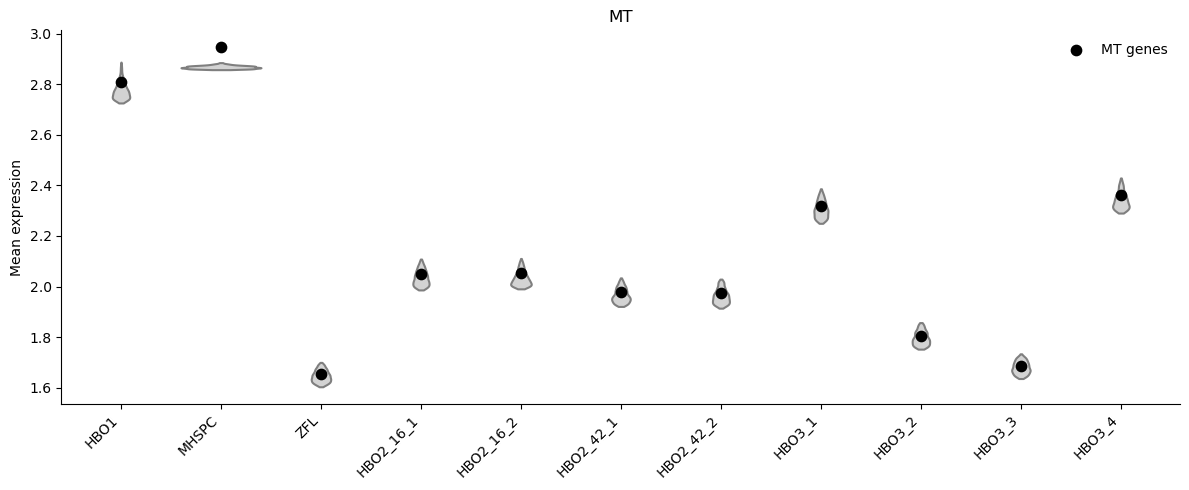

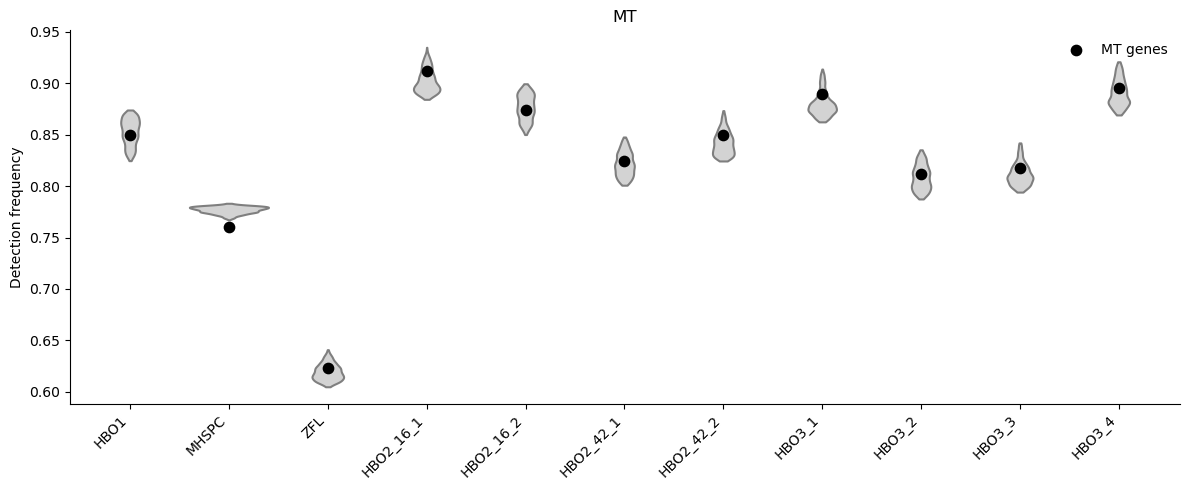

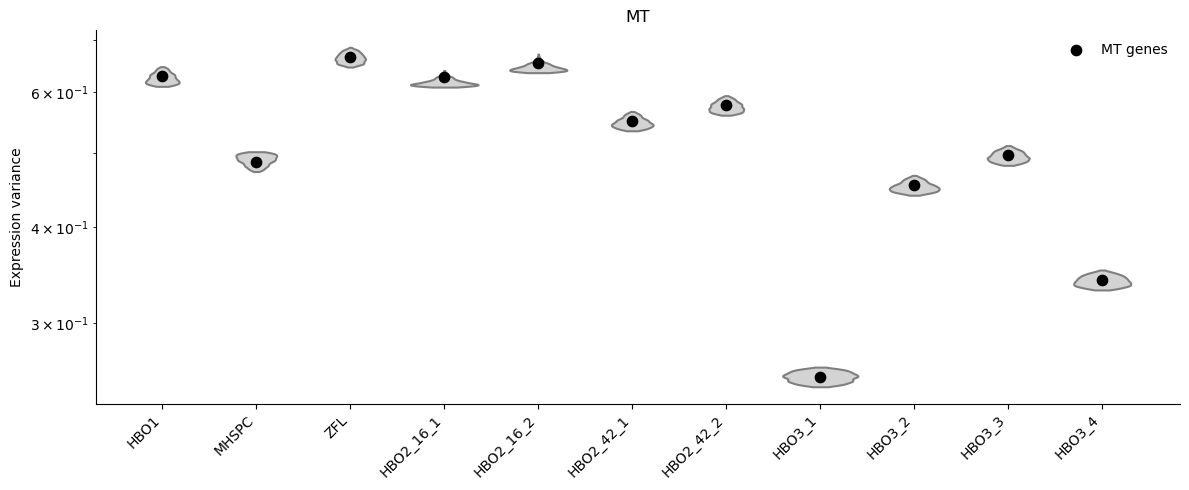

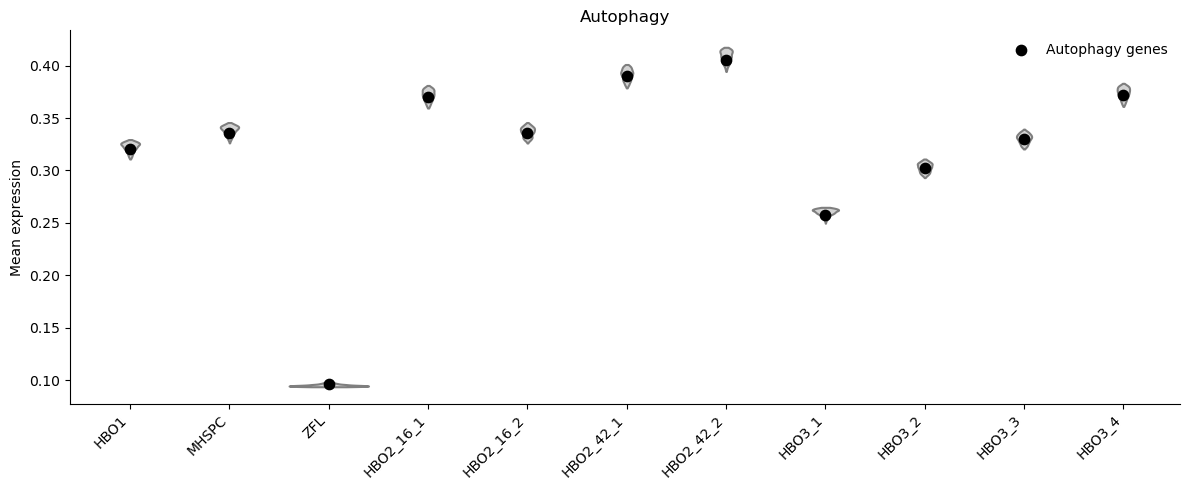

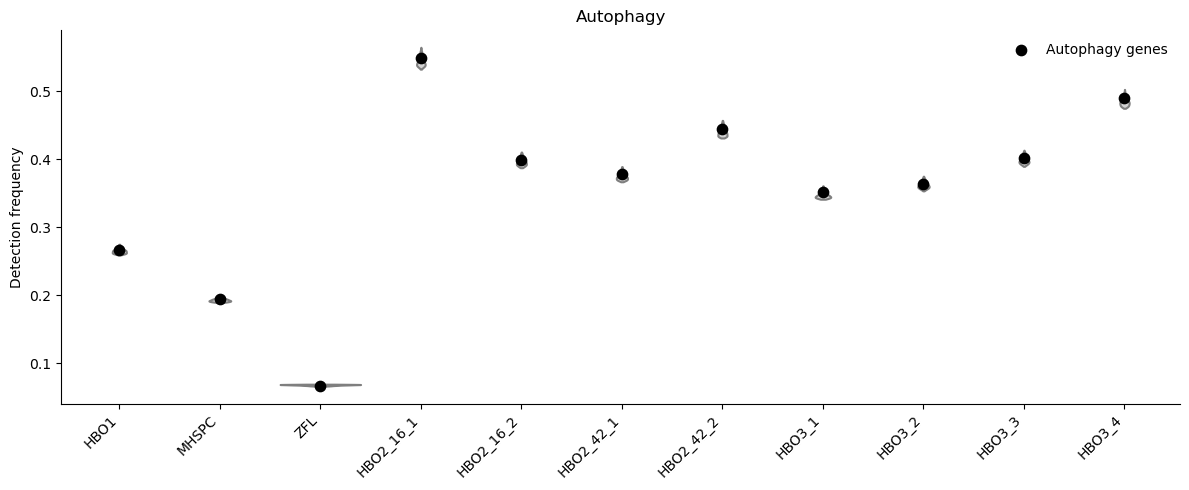

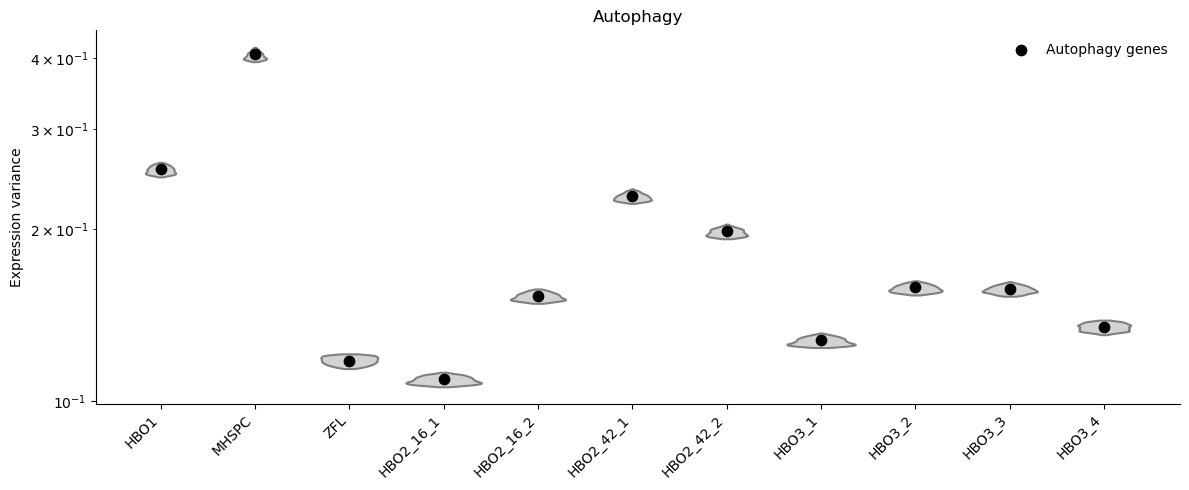

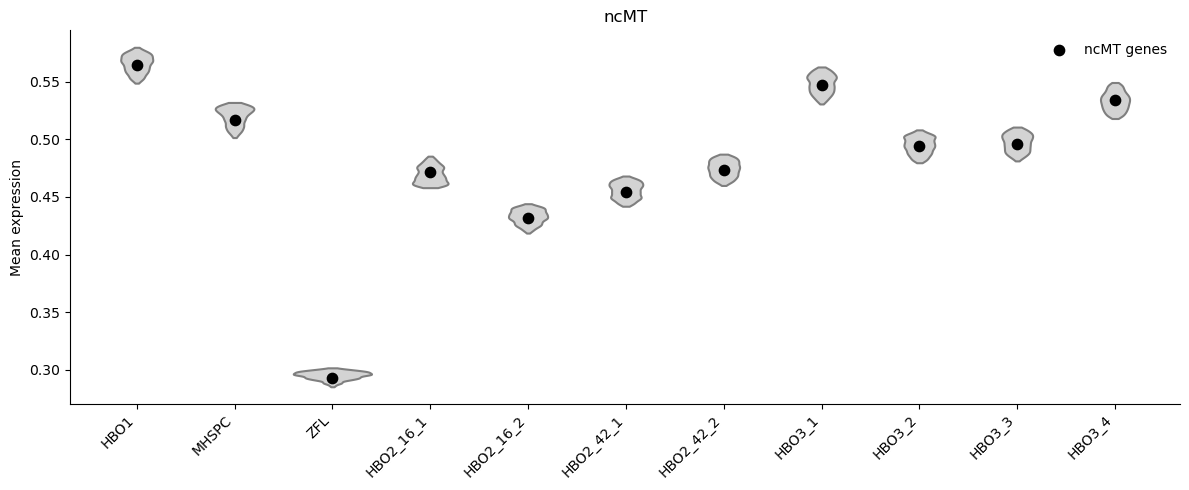

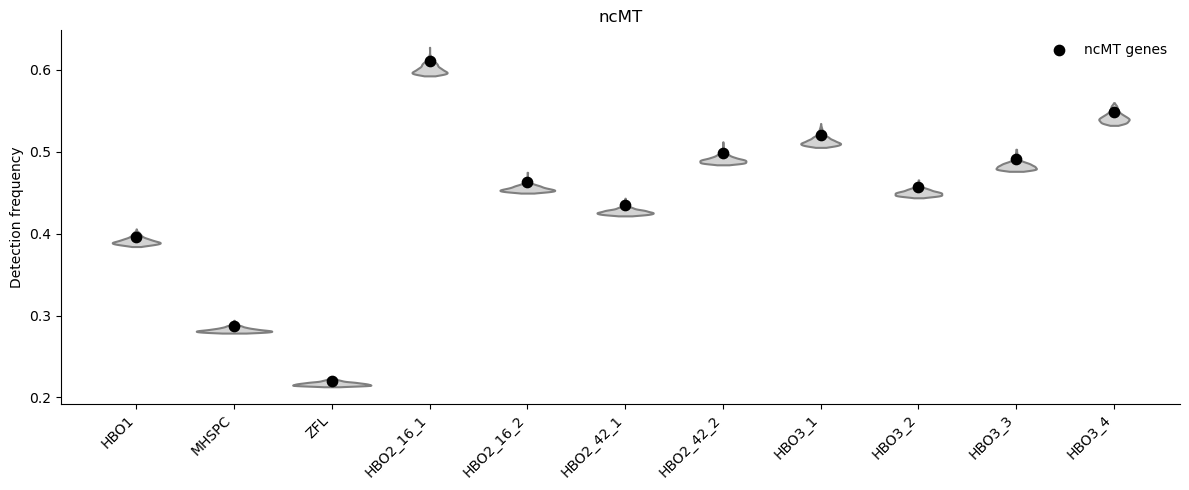

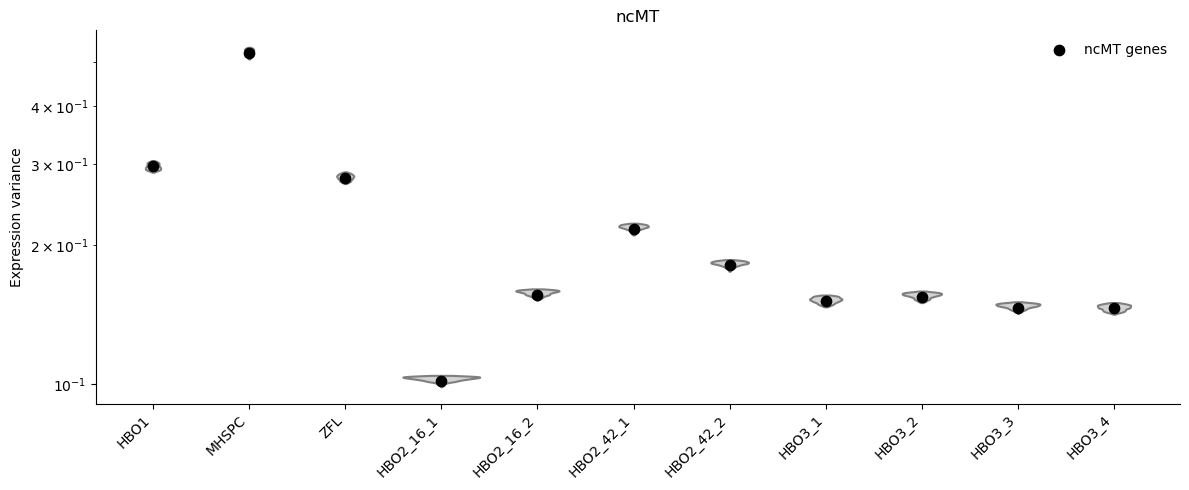

In [16]:
def plot_matching_qc(gene_set, metric, ylabel, log_scale=False):
    plot_sets = matched_set_qc_final.loc[
        matched_set_qc_final["gene_set"] == gene_set
    ].copy()

    plot_obs = observed_qc_final.loc[
        observed_qc_final["gene_set"] == gene_set
    ].copy()

    fig, ax = plt.subplots(figsize=(12, 5))

    sns.violinplot(
        data=plot_sets,
        x="dataset_label",
        y=metric,
        order=dataset_order,
        inner=None,
        cut=0,
        color="lightgray",
        ax=ax,
    )

    for i, dataset_label in enumerate(dataset_order):
        value = plot_obs.loc[
            plot_obs["dataset_label"] == dataset_label,
            metric,
        ].iloc[0]

        ax.scatter(
            i,
            value,
            color="black",
            s=55,
            zorder=5,
            label=f"{gene_set} genes" if i == 0 else None,
        )

    ax.set_title(gene_set)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)

    if log_scale:
        ax.set_yscale("log")

    plt.xticks(rotation=45, ha="right")
    ax.grid(False)
    sns.despine(ax=ax)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(
        f"/fast/AG_Metzger/philipp/python_files/"
        f"gene_signature/mutual_information_approach/"
        f"November_25_ReDo/figures/"
        f"matching_qc_{gene_set}_{metric}.pdf",
        bbox_inches="tight"
    )
    plt.show()


for gene_set in GENE_SET_ORDER:
    plot_matching_qc(gene_set, "mean_expression", "Mean expression")
    plot_matching_qc(gene_set, "detection_frequency", "Detection frequency")
    plot_matching_qc(
        gene_set,
        "expression_variance",
        "Expression variance",
        log_scale=True,
    )


## Compare MI of observed vs expression-matched gene sets

This section mirrors the MT notebook and uses `true_mi`. For each observed gene set, the empirical one-sided test asks whether its mean MI is higher than the distribution of mean MI from the 1,000 expression/detection/variance-matched control sets.

In [10]:
MI_COL = "true_mi"

MI_DIR = Path(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

MI_MATCH_OUT_DIR = MATCH_OUT_DIR / "MI_results"
MI_MATCH_OUT_DIR.mkdir(parents=True, exist_ok=True)

all_summaries = []

for dataset, pkl_path in file_dict.items():
    print("\n" + "=" * 80)
    print(dataset, "|", name_map[dataset])
    print("=" * 80)

    mi_path = MI_DIR / f"MI_label_entropy_{dataset}_50_permutations.csv"
    mi_df = pd.read_csv(mi_path)

    if "gene" not in mi_df.columns or MI_COL not in mi_df.columns:
        raise ValueError(
            f"{dataset}: required columns gene/{MI_COL} missing. "
            f"Columns: {list(mi_df.columns)}"
        )

    mi_lookup = (
        mi_df[["gene", MI_COL]]
        .assign(gene=lambda x: x["gene"].astype(str))
        .groupby("gene", as_index=False)[MI_COL]
        .max()
        .set_index("gene")[MI_COL]
    )

    full_df = pd.read_pickle(pkl_path)
    gene_stats = calculate_gene_covariates(full_df)
    del full_df

    for gene_set in GENE_SET_ORDER:
        print("\n", gene_set)

        target_df, _ = get_target_and_control_df(gene_stats, gene_set)
        target_genes = target_df["gene"].astype(str).tolist()

        missing_target = [g for g in target_genes if g not in mi_lookup.index]
        if missing_target:
            raise ValueError(
                f"{dataset} / {gene_set}: target genes missing MI: {missing_target}"
            )

        target_mi_values = mi_lookup.loc[target_genes].to_numpy()
        observed_mean_mi = target_mi_values.mean()
        observed_median_mi = np.median(target_mi_values)

        matched_genes_path = (
            MATCH_OUT_DIR / gene_set / f"{dataset}_matched_gene_sets_FINAL.csv"
        )
        matched_genes = pd.read_csv(matched_genes_path)
        matched_genes["gene"] = matched_genes["gene"].astype(str)
        matched_genes["mi"] = matched_genes["gene"].map(mi_lookup)

        n_missing = matched_genes["mi"].isna().sum()
        if n_missing > 0:
            missing_genes = matched_genes.loc[
                matched_genes["mi"].isna(), "gene"
            ].unique()
            raise ValueError(
                f"{dataset} / {gene_set}: matched genes missing MI: {missing_genes}"
            )

        matched_set_mi = (
            matched_genes
            .groupby("set_id", as_index=False)
            .agg(
                mean_mi=("mi", "mean"),
                median_mi=("mi", "median"),
                n_genes=("gene", "nunique"),
            )
        )

        if len(matched_set_mi) != N_MATCHED_SETS:
            raise ValueError(
                f"{dataset} / {gene_set}: found {len(matched_set_mi)} MI sets, "
                f"expected {N_MATCHED_SETS}."
            )

        if not (matched_set_mi["n_genes"] == len(target_genes)).all():
            raise ValueError(
                f"{dataset} / {gene_set}: matched-set gene counts do not equal "
                f"observed set size {len(target_genes)}."
            )

        n_sets = len(matched_set_mi)

        empirical_p_mean = (
            1 + np.sum(matched_set_mi["mean_mi"] >= observed_mean_mi)
        ) / (n_sets + 1)

        empirical_p_median = (
            1 + np.sum(matched_set_mi["median_mi"] >= observed_median_mi)
        ) / (n_sets + 1)

        matched_mean_mi = matched_set_mi["mean_mi"].mean()
        matched_median_mi = matched_set_mi["median_mi"].mean()

        mi_ratio = observed_mean_mi / matched_mean_mi
        mi_difference = observed_mean_mi - matched_mean_mi

        matched_set_mi.to_csv(
            MI_MATCH_OUT_DIR /
            f"{dataset}_{gene_set}_expression_matched_MI_distribution.csv",
            index=False,
        )

        all_summaries.append({
            "dataset": dataset,
            "dataset_label": name_map[dataset],
            "gene_set": gene_set,
            "n_target_genes": len(target_genes),
            "n_matched_sets": n_sets,
            "observed_mean_MI": observed_mean_mi,
            "matched_mean_MI": matched_mean_mi,
            "MI_difference": mi_difference,
            "MI_ratio_observed_over_matched": mi_ratio,
            "empirical_p_mean": empirical_p_mean,
            "observed_median_MI": observed_median_mi,
            "matched_median_MI": matched_median_mi,
            "empirical_p_median": empirical_p_median,
        })

        print("Observed mean MI:", observed_mean_mi)
        print("Matched mean MI:", matched_mean_mi)
        print("Ratio:", mi_ratio)
        print("Empirical one-sided p:", empirical_p_mean)



treutlein | HBO1

 MT
Observed mean MI: 1.8623838933996724
Matched mean MI: 1.6842394847301572
Ratio: 1.1057714240074694
Empirical one-sided p: 0.000999000999000999

 Autophagy
Observed mean MI: 0.674339282402059
Matched mean MI: 0.6478912359003002
Ratio: 1.0408217383354583
Empirical one-sided p: 0.13986013986013987

 ncMT
Observed mean MI: 0.8510722817354277
Matched mean MI: 0.8292508628656562
Ratio: 1.0263146170199484
Empirical one-sided p: 0.09290709290709291

weinreb | MHSPC

 MT
Observed mean MI: 1.20175267883406
Matched mean MI: 1.2840226155217096
Ratio: 0.9359279691080654
Empirical one-sided p: 1.0

 Autophagy
Observed mean MI: 0.5814940215534016
Matched mean MI: 0.5501560399515076
Ratio: 1.0569619877383445
Empirical one-sided p: 0.1068931068931069

 ncMT
Observed mean MI: 0.7338307336852
Matched mean MI: 0.695119190595932
Ratio: 1.0556905112288446
Empirical one-sided p: 0.11488511488511488

junker | ZFL

 MT
Observed mean MI: 0.45054009442525367
Matched mean MI: 0.426118042104

## Multiple-testing correction

Two BH columns are saved deliberately:

- `p_BH_within_gene_set`: 11 tests at a time. This is the direct analogue of the MT-only notebook, which corrected across the 11 datasets for the MT hypothesis.
- `p_BH_all_33`: all 3 gene sets × 11 datasets together (33 tests), if you regard all three gene-set analyses as one hypothesis family.

This avoids silently choosing one family definition for you.

In [11]:
mi_summary_df = pd.DataFrame(all_summaries)

# ============================================================
# BH within each gene set: 11 dataset-level tests at a time
# ============================================================

mi_summary_df["p_BH_within_gene_set"] = np.nan

for gene_set, idx in mi_summary_df.groupby("gene_set").groups.items():
    mi_summary_df.loc[idx, "p_BH_within_gene_set"] = multipletests(
        mi_summary_df.loc[idx, "empirical_p_mean"],
        method="fdr_bh",
    )[1]

# ============================================================
# BH across all 33 gene-set × dataset tests
# ============================================================

mi_summary_df["p_BH_all_33"] = multipletests(
    mi_summary_df["empirical_p_mean"],
    method="fdr_bh",
)[1]

mi_summary_df["significant_BH_within_gene_set"] = (
    mi_summary_df["p_BH_within_gene_set"] < 0.05
)
mi_summary_df["significant_BH_all_33"] = (
    mi_summary_df["p_BH_all_33"] < 0.05
)

# Ordering
mi_summary_df["dataset_label"] = pd.Categorical(
    mi_summary_df["dataset_label"],
    categories=dataset_order,
    ordered=True,
)
mi_summary_df["gene_set"] = pd.Categorical(
    mi_summary_df["gene_set"],
    categories=GENE_SET_ORDER,
    ordered=True,
)

mi_summary_df = (
    mi_summary_df
    .sort_values(["gene_set", "dataset_label"])
    .reset_index(drop=True)
)

summary_path = MI_MATCH_OUT_DIR / "MT_Autophagy_ncMT_expression_matched_MI_summary.csv"
mi_summary_df.to_csv(summary_path, index=False)

display(mi_summary_df)
print("Saved:", summary_path)


,dataset,dataset_label,gene_set,n_target_genes,n_matched_sets,observed_mean_MI,matched_mean_MI,MI_difference,MI_ratio_observed_over_matched,empirical_p_mean,observed_median_MI,matched_median_MI,empirical_p_median,p_BH_within_gene_set,p_BH_all_33,significant_BH_within_gene_set,significant_BH_all_33
0,treutlein,HBO1,MT,13,1000,1.862384,1.684239,0.178144,1.105771,0.000999,2.003176,1.778094,0.000999,0.003663,0.010989,True,True
1,weinreb,MHSPC,MT,13,1000,1.201753,1.284023,-0.082270,0.935928,1.000000,1.435407,1.544962,1.000000,1.000000,1.000000,False,False
2,junker,ZFL,MT,13,1000,0.450540,0.426118,0.024422,1.057313,0.035964,0.534058,0.481184,0.028971,0.079121,0.131868,False,False
3,knoblich_day16_1,HBO2_16_1,MT,13,1000,0.328699,0.327499,0.001200,1.003663,0.416583,0.350396,0.333538,0.001998,0.458242,0.443460,False,False
4,knoblich_day16_2,HBO2_16_2,MT,13,1000,0.257324,0.249714,0.007611,1.030478,0.082917,0.275815,0.252209,0.000999,0.130298,0.161365,False,False
5,knoblich_day42_1,HBO2_42_1,MT,13,1000,0.137553,0.135034,0.002519,1.018654,0.171828,0.139018,0.146597,0.966034,0.236264,0.218090,False,False
6,knoblich_day42_2,HBO2_42_2,MT,13,1000,0.234254,0.228128,0.006127,1.026856,0.081918,0.238033,0.235397,0.378621,0.130298,0.161365,False,False
7,you1,HBO3_1,MT,13,1000,3.809954,3.538523,0.271432,1.076708,0.000999,4.062013,3.631332,0.000999,0.003663,0.010989,True,True
8,you2,HBO3_2,MT,13,1000,3.561663,3.370154,0.191510,1.056825,0.026973,4.011997,3.472629,0.000999,0.074176,0.127159,False,False
9,you3,HBO3_3,MT,13,1000,3.302046,3.050917,0.251129,1.082313,0.000999,3.709125,3.192561,0.000999,0.003663,0.010989,True,True


Saved: /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/analysis/MT_autophagy_ncMT_expression_matching/MI_results/MT_Autophagy_ncMT_expression_matched_MI_summary.csv


## MI-ratio plots

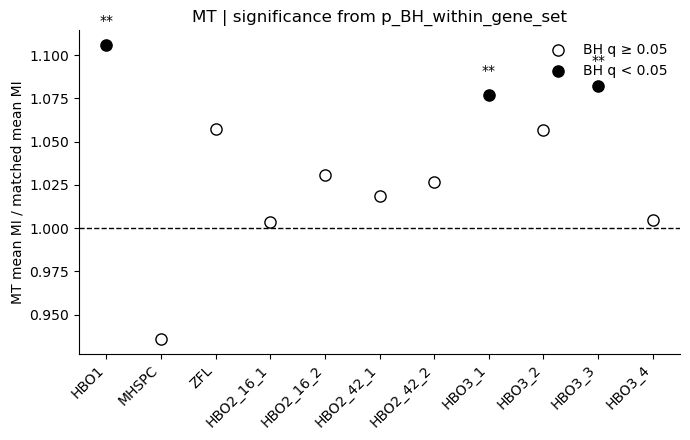

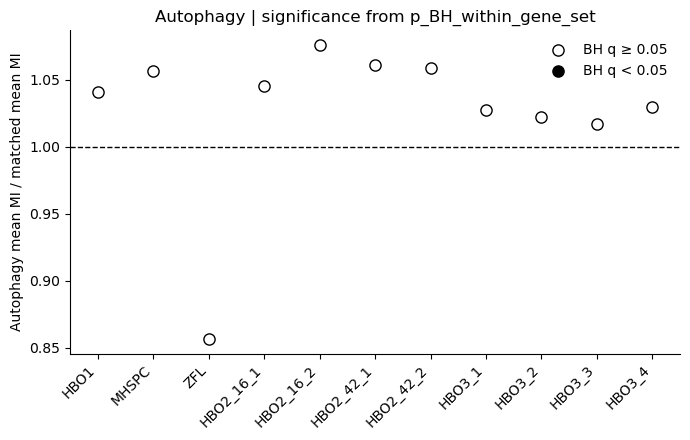

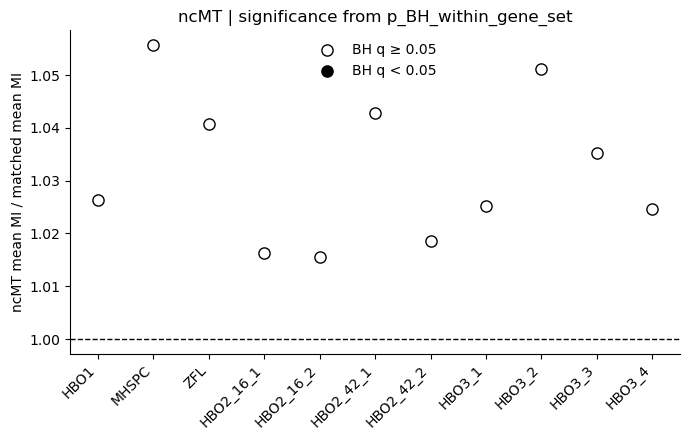

In [14]:
def plot_mi_ratio(gene_set, q_col="p_BH_all_33"):
    plot_df = (
        mi_summary_df.loc[mi_summary_df["gene_set"] == gene_set]
        .copy()
        .sort_values("dataset_label")
        .reset_index(drop=True)
    )

    fig, ax = plt.subplots(figsize=(7, 4.5))
    x = np.arange(len(plot_df))

    ax.axhline(1, linestyle="--", linewidth=1, color="black")

    sig = plot_df[q_col] < 0.05
    ns = ~sig

    ax.scatter(
        x[ns],
        plot_df.loc[ns, "MI_ratio_observed_over_matched"],
        facecolors="white",
        edgecolors="black",
        s=65,
        zorder=3,
        label="BH q ≥ 0.05",
    )

    ax.scatter(
        x[sig],
        plot_df.loc[sig, "MI_ratio_observed_over_matched"],
        color="black",
        s=65,
        zorder=3,
        label="BH q < 0.05",
    )

    for i, row in plot_df.iterrows():
        q = row[q_col]

        if q < 0.001:
            stars = "***"
        elif q < 0.01:
            stars = "**"
        elif q < 0.05:
            stars = "*"
        else:
            stars = ""

        if stars:
            ax.text(
                i,
                row["MI_ratio_observed_over_matched"] + 0.01,
                stars,
                ha="center",
                va="bottom",
            )

    ax.set_xticks(x)
    ax.set_xticklabels(plot_df["dataset_label"], rotation=45, ha="right")
    ax.set_ylabel(f"{gene_set} mean MI / matched mean MI")
    ax.set_xlabel("")
    ax.set_title(f"{gene_set} | significance from {q_col}")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)

    plt.tight_layout()
    
    plt.savefig(
    f"MI_ratio_{gene_set}_BH_11tests.pdf",
    bbox_inches="tight"
    )

    
    plt.show()


# Primary view: correction across all 33 tests.
# Change q_col to "p_BH_within_gene_set" to reproduce the
# 11-test family used by the old MT-only notebook.
for gene_set in GENE_SET_ORDER:
    plot_mi_ratio(gene_set, q_col="p_BH_within_gene_set")


## Optional: compact result table

In [ ]:
display(
    mi_summary_df[[
        "gene_set",
        "dataset_label",
        "n_target_genes",
        "observed_mean_MI",
        "matched_mean_MI",
        "MI_ratio_observed_over_matched",
        "empirical_p_mean",
        "p_BH_within_gene_set",
        "p_BH_all_33",
    ]]
)
